In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt

In [2]:
# Read the CSV file into a DataFrame
db_path = os.path.join("dados", "eCommerce-dataset.csv")
df = pd.read_csv(db_path) #enconding is necessary?
before = len(df)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  str    
 2   Country                        50000 non-null  str    
 3   City                           50000 non-null  str    
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  int64  
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       47000 non-null  float64
 1

# Turn str type feature into dummy variables

In [22]:
db_path = os.path.join("dados", "eCommerce-dataset.csv")
df = pd.read_csv(db_path) #enconding is necessary?

df["Signup_Quarter"] = df["Signup_Quarter"].astype("category")
df = pd.get_dummies(df, columns=["Gender", "Signup_Quarter", "Country", "City"], dtype="int", drop_first=True)

df.head(5)

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,...,City_Ottawa,City_Paris,City_Perth,City_Phoenix,City_Sydney,City_Tokyo,City_Toronto,City_Toulouse,City_Vancouver,City_Yokohama
0,43.0,2.9,14,27.4,6.0,50.6,3.0,9.0,94.72,34.0,...,0,0,0,0,0,0,0,0,0,0
1,36.0,1.6,15,42.7,10.3,37.7,1.0,19.5,82.45,71.0,...,0,0,0,0,0,0,0,0,0,0
2,45.0,2.9,10,24.8,1.6,70.9,1.0,9.1,165.52,11.0,...,0,0,0,0,0,0,0,0,1,0
3,56.0,2.6,10,38.4,14.8,41.7,9.0,15.0,147.33,47.0,...,0,0,0,0,0,0,0,0,0,0
4,35.0,3.1,29,51.4,NaN,19.1,9.0,32.5,141.30,73.0,...,0,0,0,0,0,0,0,0,0,0


# Fill NaN values (or deleting)

In [23]:
print("Handling missing values and correcting inconsistent records.")
# Age feature
median = df["Age"].median() # 38 years old
df["Age"] = df["Age"].fillna(median)
print(f"Age (total NaN values):",df["Age"].isnull().sum())

######################################
feature = "Session_Duration_Avg"
df[feature] = df[feature].fillna(0)
print(f"{feature} (total NaN values):",df[feature].isnull().sum())

#####################################
feature = "Pages_Per_Session"
median = df[feature].median()
df[feature] = df[feature].fillna(median)
print(f"{feature} (total NaN values):",df[feature].isnull().sum())

#####################################
feature = "Wishlist_Items"
df[feature] = df[feature].fillna(0)
print(f"{feature} (total NaN values):",df[feature].isnull().sum())

#####################################
feature = "Days_Since_Last_Purchase"
df[feature] = df[feature].fillna(df[feature].max()+10)
print(f"{feature} (total NaN values):",df[feature].isnull().sum())

####################################
feature = "Total_Purchases"
df = df[df[feature] >= 0]
after = len(df)
print(f"After deleting negative Total_Purchases: {after}/{before}")

########################################
for feature in ["Discount_Usage_Rate",
                "Returns_Rate",
                "Email_Open_Rate",
                "Customer_Service_Calls",
                "Product_Reviews_Written",
                "Social_Media_Engagement_Score",
                "Mobile_App_Usage",
                "Payment_Method_Diversity",
                "Credit_Balance"]:
    
    df[feature] = df[feature].fillna(0)
    print(f"{feature} (total NaN values):",df[feature].isnull().sum())

Handling missing values and correcting inconsistent records.
Age (total NaN values): 0
Session_Duration_Avg (total NaN values): 0
Pages_Per_Session (total NaN values): 0
Wishlist_Items (total NaN values): 0
Days_Since_Last_Purchase (total NaN values): 0
After deleting negative Total_Purchases: 49960/50000
Discount_Usage_Rate (total NaN values): 0
Returns_Rate (total NaN values): 0
Email_Open_Rate (total NaN values): 0
Customer_Service_Calls (total NaN values): 0
Product_Reviews_Written (total NaN values): 0
Social_Media_Engagement_Score (total NaN values): 0
Mobile_App_Usage (total NaN values): 0
Payment_Method_Diversity (total NaN values): 0
Credit_Balance (total NaN values): 0


In [24]:
features = df.columns.to_list()
features.remove("Churned")
X = df[features]
Y = df["Churned"]
print(f"len(X.columns): {len(X.columns)}")

len(X.columns): 71


# Logistic Regression with Lasso ridge

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=23, stratify=Y)
Y_train.value_counts()

print(f"X_train/X_test: {len(X_train)}/{len(X_test)}\nY_train/Y_test: {len(Y_train)}/{len(Y_test)}")
print(f"Train|  0 1:", *(Y_train.value_counts()).values)
print(f"Test |  0 1:", *(Y_test.value_counts()).values)

X_train/X_test: 39968/9992
Y_train/Y_test: 39968/9992
Train|  0 1: 28414 11554
Test |  0 1: 7103 2889


In [26]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold

# Grade de candidatos para C em escala logarítmica (inverso de alpha)
Cs = np.logspace(-4, 4, 10)

# Validação cruzada estratificada (5 folds)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Pipeline: padronização + regressão logística com Lasso (L1)
modelo_lasso = make_pipeline(
    StandardScaler(),
    LogisticRegressionCV(
        Cs=Cs,
        cv=cv,
        penalty='l1',
        solver='saga',
        scoring='roc_auc',  # ou 'accuracy'
        random_state=42,
        max_iter=5000
    )
)

# Ajuste apenas no conjunto de treino
modelo_lasso.fit(X_train, Y_train)

c:\Users\gugam\miniconda3\envs\data_analysis-env\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\gugam\miniconda3\envs\data_analysis-env\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
c:\Users\gugam\miniconda3\envs\data_analysis-env\Lib\site-packages\sklearn\linear_model\_logistic

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregressioncv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](71,)","['Age','Membership_Years','Login_Frequency',...,'City_Toulouse', 'City_Vancouver','City_Yokohama']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,71
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [27]:
from sklearn.metrics import classification_report, roc_auc_score

# Previsão de probabilidades para a classe positiva (1)
y_prob = modelo_lasso.predict_proba(X_test)[:, 1]
y_pred = modelo_lasso.predict(X_test)
auc = roc_auc_score(Y_test, y_prob)

print(f"AUC final no teste: {roc_auc_score(Y_test, y_prob):.2f}")
print(classification_report(Y_test, y_pred))

AUC final no teste: 0.77
              precision    recall  f1-score   support

           0       0.78      0.92      0.85      7103
           1       0.66      0.37      0.47      2889

    accuracy                           0.76      9992
   macro avg       0.72      0.64      0.66      9992
weighted avg       0.75      0.76      0.74      9992



opt_threshold: 0.3040224932751258


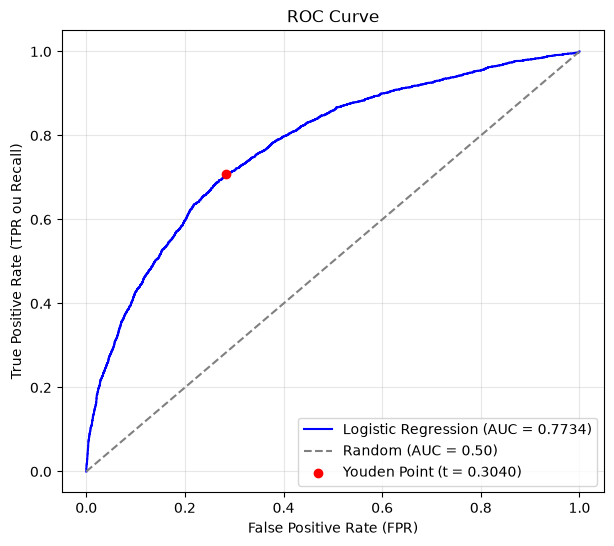

In [28]:
from sklearn.metrics import roc_curve

fpr, tpr, threshold_roc = roc_curve(Y_test, y_prob)

j_score = tpr - fpr
opt_index = np.argmax(j_score)
opt_threshold = threshold_roc[opt_index]

print(f"opt_threshold: {opt_threshold}")

# 4. Plota a Curva ROC destacando o ponto de Youden
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.4f})", color="blue")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random (AUC = 0.50)")
plt.scatter(fpr[opt_index], tpr[opt_index], color="red", zorder=5,
            label=f"Youden Point (t = {opt_threshold:.4f})")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR ou Recall)")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
regressor = modelo_lasso.named_steps["logisticregressioncv"]
features = X_train.columns
coeff = regressor.coef_[0]

results = pd.DataFrame({"features": features, "coeff": np.round(coeff, 3)})
results_sorted = results.sort_values(by="coeff", ascending=False)
results_sorted.head(10)

,features,coeff
18,Lifetime_Value,0.773
13,Customer_Service_Calls,0.548
5,Cart_Abandonment_Rate,0.544
11,Returns_Rate,0.202
9,Days_Since_Last_Purchase,0.166
24,Signup_Quarter_Q4,0.032
63,City_Perth,0.017
36,City_Calgary,0.016
67,City_Toronto,0.015
21,Gender_Other,0.012


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Lifetime_Value'),
  Text(1, 0, 'Customer_Service_Calls'),
  Text(2, 0, 'Cart_Abandonment_Rate'),
  Text(3, 0, 'Returns_Rate'),
  Text(4, 0, 'Days_Since_Last_Purchase'),
  Text(5, 0, 'Signup_Quarter_Q4'),
  Text(6, 0, 'City_Perth'),
  Text(7, 0, 'City_Calgary'),
  Text(8, 0, 'City_Toronto'),
  Text(9, 0, 'Gender_Other')])

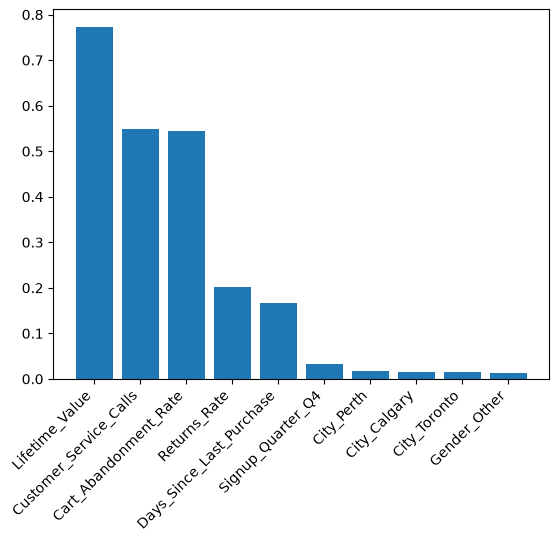

In [64]:
plt.bar(x=results_sorted["features"].head(10), height=results_sorted["coeff"].head(10))
plt.xticks(rotation=45, ha='right')

In [58]:
results_sorted[np.abs(results_sorted["coeff"]) < 0.1]

,features,coeff
24,Signup_Quarter_Q4,0.032
63,City_Perth,0.017
36,City_Calgary,0.016
67,City_Toronto,0.015
21,Gender_Other,0.012
...,...,...
41,City_Frankfurt,-0.021
16,Mobile_App_Usage,-0.021
15,Social_Media_Engagement_Score,-0.025
3,Session_Duration_Avg,-0.029


In [65]:
import numpy as np
import pandas as pd

regressor = modelo_lasso.named_steps["logisticregressioncv"]
scaler = modelo_lasso.named_steps["standardscaler"]

results = pd.DataFrame({
    "feature": X_train.columns,
    "coeff_padronizado": regressor.coef_[0],
    "desvio_padrao_X": scaler.scale_,
    "odds_ratio_1sd": np.exp(regressor.coef_[0]),
    "impacto_odds_pct": (np.exp(regressor.coef_[0]) - 1) * 100
})

# Os 10 maiores fatores de retenção (coeficientes mais negativos)
top_retencao = results.sort_values(by="coeff_padronizado", ascending=True).head(10)
print("=== TOP 10 FATORES DE RETENÇÃO (PESOS NEGATIVOS) ===")
print(top_retencao.round(4).to_string(index=False))

# Para comparação direta, os 5 maiores fatores de risco (pesos positivos)
top_risco = results.sort_values(by="coeff_padronizado", ascending=False).head(5)
print("\n=== TOP 5 FATORES DE RISCO (PESOS POSITIVOS) ===")
print(top_risco.round(4).to_string(index=False))

=== TOP 10 FATORES DE RETENÇÃO (PESOS NEGATIVOS) ===
                      feature  coeff_padronizado  desvio_padrao_X  odds_ratio_1sd  impacto_odds_pct
                          Age            -0.2845          11.5755          0.7524          -24.7628
              Total_Purchases            -0.2641           7.0682          0.7679          -23.2097
              Email_Open_Rate            -0.2188          14.6454          0.8035          -19.6541
          Discount_Usage_Rate            -0.1512          23.1909          0.8597          -14.0330
            Pages_Per_Session            -0.1417           3.6645          0.8679          -13.2080
      Product_Reviews_Written            -0.0490           2.3535          0.9522           -4.7774
         Session_Duration_Avg            -0.0285          12.5785          0.9719           -2.8105
Social_Media_Engagement_Score            -0.0253          21.4981          0.9750           -2.4964
             Mobile_App_Usage            -0.021

=== COMPARAÇÃO DE BENCHMARK NO CONJUNTO DE TESTE ===
                          Modelo  ROC-AUC  PR-AUC  Log-Loss  Threshold Youden  Recall (Youden)  FPR (Youden)
  Logistic Regression (Lasso L1)   0.7734  0.5985    0.5020            0.3040           0.7085        0.2833
HistGradientBoosting (Benchmark)   0.9306  0.9112    0.2418            0.3059           0.8667        0.0701


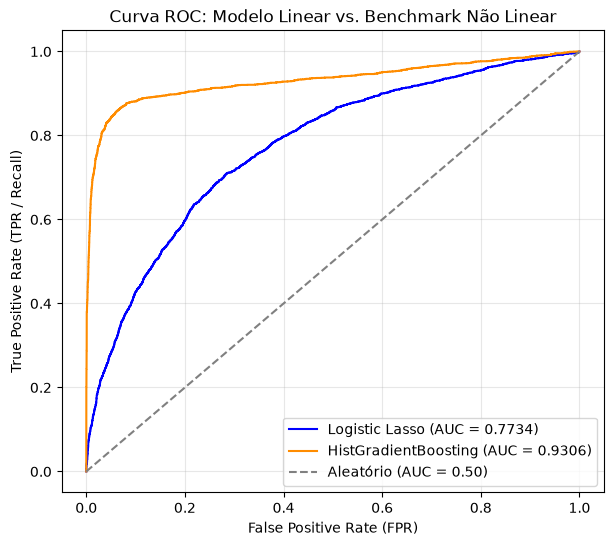

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    roc_curve,
    classification_report
)

# 1. Instancia e treina o modelo não linear (Gradient Boosting)
# Nota: árvores são invariantes à escala, então não precisam do StandardScaler
modelo_gb = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    min_samples_leaf=50,      # Evita overfitting nas folhas em N ~ 40k
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

modelo_gb.fit(X_train, Y_train)

# 2. Predições probabilísticas no conjunto de teste
y_prob_lasso = modelo_lasso.predict_proba(X_test)[:, 1]
y_prob_gb    = modelo_gb.predict_proba(X_test)[:, 1]

# 3. Tabela comparativa direta: Regressão Logística Lasso vs. Gradient Boosting
def resumir_modelo(nome, y_true, y_prob):
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    best_idx = np.argmax(tpr - fpr)
    t_youden = thresholds[best_idx]
    
    return {
        "Modelo": nome,
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Log-Loss": log_loss(y_true, y_prob),
        "Threshold Youden": t_youden,
        "Recall (Youden)": tpr[best_idx],
        "FPR (Youden)": fpr[best_idx]
    }

df_comp = pd.DataFrame([
    resumir_modelo("Logistic Regression (Lasso L1)", Y_test, y_prob_lasso),
    resumir_modelo("HistGradientBoosting (Benchmark)", Y_test, y_prob_gb)
])

print("=== COMPARAÇÃO DE BENCHMARK NO CONJUNTO DE TESTE ===")
print(df_comp.round(4).to_string(index=False))

# 4. Sobreposição das Curvas ROC
fpr_l, tpr_l, _ = roc_curve(Y_test, y_prob_lasso)
fpr_g, tpr_g, _ = roc_curve(Y_test, y_prob_gb)

plt.figure(figsize=(7, 6))
plt.plot(fpr_l, tpr_l, label=f"Logistic Lasso (AUC = {roc_auc_score(Y_test, y_prob_lasso):.4f})", color="blue")
plt.plot(fpr_g, tpr_g, label=f"HistGradientBoosting (AUC = {roc_auc_score(Y_test, y_prob_gb):.4f})", color="darkorange")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatório (AUC = 0.50)")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR / Recall)")
plt.title("Curva ROC: Modelo Linear vs. Benchmark Não Linear")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

=== TOP 15 DRIVERS GLOBAIS NO HISTGRADIENTBOOSTING (SHAP) ===
                      feature  mean_abs_shap_logodds
       Customer_Service_Calls                 0.9705
               Lifetime_Value                 0.9569
        Cart_Abandonment_Rate                 0.4801
                          Age                 0.4213
     Days_Since_Last_Purchase                 0.3246
          Discount_Usage_Rate                 0.3171
              Email_Open_Rate                 0.2501
              Total_Purchases                 0.1713
                 Returns_Rate                 0.1629
         Session_Duration_Avg                 0.1313
            Pages_Per_Session                 0.1013
               Wishlist_Items                 0.0721
      Product_Reviews_Written                 0.0705
             Mobile_App_Usage                 0.0624
Social_Media_Engagement_Score                 0.0612


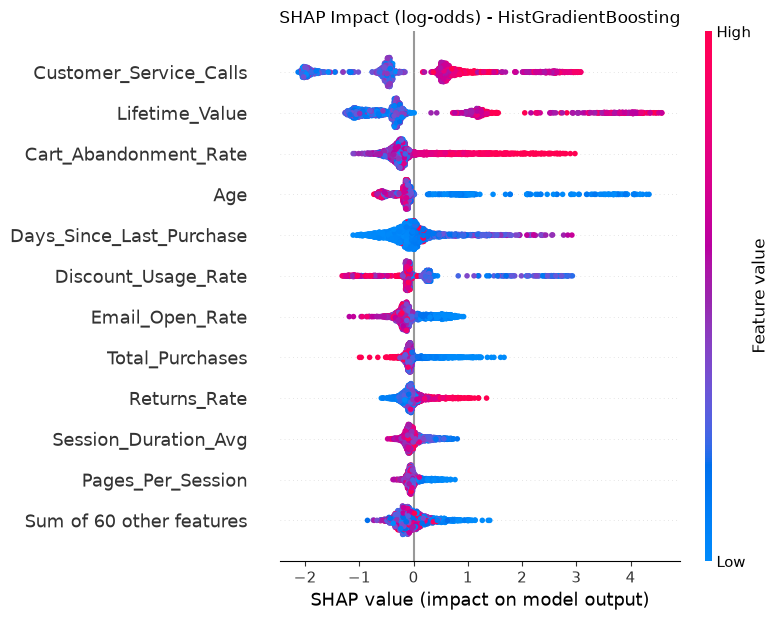

In [70]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Amostra estratificada de 2.000 observações do teste para cálculo rápido e exato
X_shap = X_test.sample(n=2000, random_state=42)

# 2. Inicializa o TreeExplainer para o HistGradientBoostingClassifier
explainer = shap.TreeExplainer(modelo_gb)
shap_values = explainer(X_shap)

# 3. Tabela de importância global (média do impacto absoluto |SHAP| em log-odds)
df_shap = pd.DataFrame({
    "feature": X_shap.columns,
    "mean_abs_shap_logodds": np.abs(shap_values.values).mean(axis=0)
}).sort_values(by="mean_abs_shap_logodds", ascending=False)

print("=== TOP 15 DRIVERS GLOBAIS NO HISTGRADIENTBOOSTING (SHAP) ===")
print(df_shap.head(15).round(4).to_string(index=False))

# 4. Beeswarm Plot: mostra direção (risco vs. retenção) e efeitos não lineares
plt.figure(figsize=(10, 7))
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP Impact (log-odds) - HistGradientBoosting")
plt.tight_layout()
plt.show()

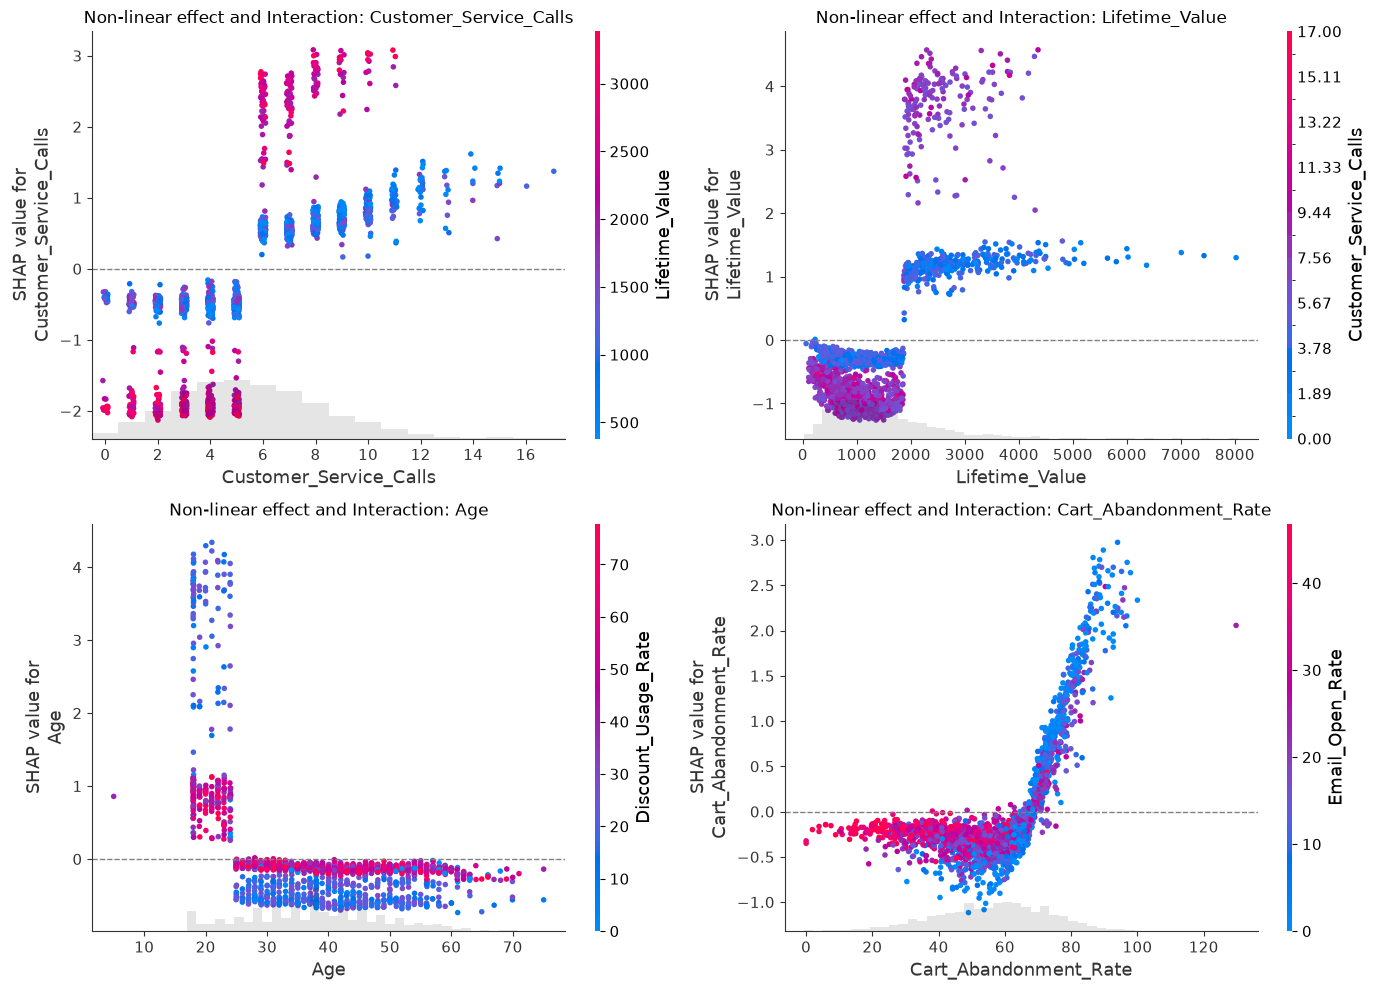

In [71]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

top_4 = ["Customer_Service_Calls", "Lifetime_Value", "Age", "Cart_Abandonment_Rate"]

for ax, feat in zip(axes.ravel(), top_4):
    shap.plots.scatter(
        shap_values[:, feat],
        color=shap_values,  # Colore automaticamente pela variável de maior interação
        ax=ax,
        show=False
    )
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"Non-linear effect and Interaction: {feat}")

plt.tight_layout()
plt.show()

In [69]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss

net = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        alpha=1e-3,          # regularização L2 (Ridge)
        early_stopping=True,
        random_state=42
    )
)

net.fit(X_train, Y_train)
y_prob_mlp = net.predict_proba(X_test)[:, 1]

print(f"MLP (64, 32) -> ROC-AUC: {roc_auc_score(Y_test, y_prob_mlp):.4f} | "
      f"PR-AUC: {average_precision_score(Y_test, y_prob_mlp):.4f} | "
      f"Log-Loss: {log_loss(Y_test, y_prob_mlp):.4f}")

MLP (64, 32) -> ROC-AUC: 0.9076 | PR-AUC: 0.8555 | Log-Loss: 0.3248
